## Task 1.3: Línea Base del Modelo Híbrido Generada por IA

A continuación se presenta el código de la línea base generado por la IA, junto con el prompt utilizado.

### a. Prompt utilizado y código base

**Prompt entregado a la IA:**
> "Escribe un modelo híbrido en Python que simule una plataforma de video durante 100 días. Combina System Dynamics (SD) para los usuarios activos y Discrete Event Simulation (DES) para los servidores. 
> Ecuación SD (días): dU/dt = (0.002 + 0.20*(U/20000))*(20000 - U) - delta * U. 
> Donde delta = 0.003 + 1.0*max(0, W - 0.75) + 0.5*r. U(0)=100.
> Capa DES (segundos, simulada cada H=1 día): Cola M/M/c/K con K=60. Llegadas Poisson con lambda = 0.0005*U. Servicio exponencial con media 0.5s (mu=2). Simula 720s, descarta 120s de calentamiento y devuelve latencia promedio W (de las aceptadas) y fracción rechazada r.
> Autoescalado: Si la utilización prevista (0.0005*U / (c*2)) > 0.7 y no hay pedido pendiente, se piden 2 servidores que llegan en D=3 días. Servidores iniciales c=4.
> Haz un bucle diario que acople ambos modelos."

In [ ]:
# Presentacion: S15 - DES e Hbridos P1
# Diapositiva 4 - Acoplamiento de modelos: DES entrega latencia y rechazo, SD actualiza los usuarios.
# Contenido: El modelo hibrido intercambia metricas de la plataforma cada dia para representar la retroalimentacion entre demanda y capacidad.
# Presentacion: S16 - DES e Hbridos P2
# Diapositiva 4 - Cuando vale la pena un hibrido: una dinamica agregada y lenta alimenta una operacion detallada y rapida.
# Contenido: El codigo deja la poblacion de usuarios en SD y modela con DES el detalle de servidores, colas y latencias.
import numpy as np
import simpy
import random

# Parámetros globales
M = 20000
p = 0.002
q = 0.20
delta_0 = 0.003
kappa_W = 1.0
kappa_R = 0.5
W_ok = 0.75
a = 0.0005
mu = 2.0
K = 60
H = 1
D = 3
theta = 0.7

# Presentacion: S15 - DES e Hbridos P1
# Diapositiva 6 - Cola M/M/c/K: llegadas Poisson, servicio exponencial, c servidores y capacidad K.
# Contenido: Esta funcion simula una ventana de 720 segundos, descarta el calentamiento y devuelve la latencia W y el rechazo r.
# Presentacion: S16 - DES e Hbridos P2
# Diapositiva 7 - De tasas a personas y de personas a tasas: una tasa lambda genera entidades discretas.
# Contenido: La tasa lambda = a * U se transforma en llegadas Poisson y las entidades completadas o rechazadas producen metricas para SD.
def simulate_des(U, c):
    env = simpy.Environment()
    servers = simpy.Resource(env, capacity=c)
    lam = a * U
    
    metrics = {'arrived': 0, 'accepted': 0, 'latencies': []}
    
    def source(env, servers, metrics):
        while True:
            yield env.timeout(random.expovariate(lam) if lam > 0 else float('inf'))
            metrics['arrived'] += 1
            env.process(customer(env, servers, metrics))
            
    def customer(env, servers, metrics):
        if servers.count + len(servers.queue) < K:
            metrics['accepted'] += 1
            arrival_time = env.now
            with servers.request() as req:
                yield req
                yield env.timeout(random.expovariate(mu))
                if env.now > 120: # Descartar calentamiento
                    metrics['latencies'].append(env.now - arrival_time)
                    
    env.process(source(env, servers, metrics))
    env.run(until=720)
    
    W = np.mean(metrics['latencies']) if metrics['latencies'] else 0.0
    r = 1.0 - (metrics['accepted'] / metrics['arrived']) if metrics['arrived'] > 0 else 0.0
    return W, r

# Simulación acoplada
dias = 100
U = 100.0
c = 4
pedido_pendiente = 0
dias_para_llegar = 0

historico_U = []
historico_W = []
historico_r = []
historico_c = []

W, r = 0.0, 0.0

# Presentacion: S15 - DES e Hbridos P1
# Diapositiva 5 - Retroalimentacion: la calidad del servicio modifica la tasa de abandono de usuarios.
# Contenido: La capa DES se ejecuta primero y sus metricas alimentan la ecuacion diferencial de la capa SD.
# Presentacion: S16 - DES e Hbridos P2
# Diapositiva 5 - Primer patron: la cascada; un modelo produce una demanda que alimenta a un DES.
# Contenido: Este bucle extiende la cascada con retroalimentacion: W y r afectan SD, y U vuelve a determinar la demanda DES.
for dia in range(dias):
    # Capa DES
    W, r = simulate_des(U, c)
    
    # Capa SD (Euler 1 paso por día)
    delta = delta_0 + kappa_W * max(0, W - W_ok) + kappa_R * r
    dU = (p + q * (U / M)) * (M - U) - (delta * U)
    U = U + dU
    
    # Política de autoescalado
    rho_pred = (a * U) / (c * mu)
    if rho_pred > theta and pedido_pendiente == 0:
        pedido_pendiente = 2
        dias_para_llegar = D
        
    if dias_para_llegar > 0:
        dias_para_llegar -= 1
        if dias_para_llegar == 0:
            c += pedido_pendiente
            pedido_pendiente = 0
            
    historico_U.append(U)
    historico_W.append(W)
    historico_r.append(r)
    historico_c.append(c)

print(f"U(100): {historico_U[-1]:.2f}")
print(f"Servidores finales: {historico_c[-1]}")
print(f"Latencia máxima: {max(historico_W):.2f} s")
print(f"Rechazo máximo: {max(historico_r):.2f}")

U(100): 19703.01
Servidores finales: 8
Latencia máxima: 0.69 s
Rechazo máximo: 0.00


## Task 2.1: Verificación de la Capa DES aislada

Esta sección aísla el simulador de eventos discretos para verificarlo contra los resultados exactos de la teoría de colas M/M/c bajo condiciones estables y de sobrecarga, confirmando la conservación de entidades mediante la ley de Little.

### a. Simulación M/M/c estable 
Se configuran 30 réplicas independientes de una cola M/M/4 con $\lambda = 6$ y $\mu = 2$. Se descartan los primeros 120 segundos para eliminar el sesgo transitorio y se recolectan estadísticas de latencia ($W$), tiempo en cola ($W_q$) y utilización ($\rho$).

### b. M/M/c/K sobrecargada
Se simula sobrecarga con $\lambda = 10$, $c = 4$ y límite de cola $K = 60$. La fracción de rechazo se aproxima teóricamente como $1 - \frac{c\mu}{\lambda}$ (es decir, el exceso de demanda sobre la capacidad máxima).

### c. Ley de Little
La ley de Little establece que $L = \lambda_{efectiva} W$. Se verificará calculando el número promedio de entidades en el sistema ($L$) directamente del área bajo la curva de ocupación en la simulación, comparándolo con el producto de la tasa de llegada real aceptada y el tiempo promedio de permanencia.

In [3]:
# Presentacion: S15 - DES e Hbridos P1
# Diapositiva 8 - Verificacion de colas: comparar M/M/c, M/M/c/K y L = lambda_efectiva * W.
# Contenido: Las replicas independientes, el calentamiento y los intervalos de confianza permiten contrastar las metricas con la teoria.
import simpy
import random
import numpy as np
import scipy.stats as st
import math

def simulacion_des_aislada(lam, mu, c, K, duration, warmup):
    env = simpy.Environment()
    servers = simpy.Resource(env, capacity=c)
    
    metrics = {
        'arrived': 0,
        'accepted': 0,
        'latencies': [],
        'wait_times': []
    }
    
    # Para calcular L (entidades en sistema) por integral de tiempo
    system_state = {'last_time': 0, 'current_entities': 0, 'area': 0.0}
    
    def update_area():
        dt = env.now - system_state['last_time']
        if env.now > warmup:
            system_state['area'] += system_state['current_entities'] * dt
        system_state['last_time'] = env.now

    def source():
        while True:
            yield env.timeout(random.expovariate(lam))
            metrics['arrived'] += 1
            env.process(customer())

    def customer():
        update_area()
        # Capacidad total = servidores + cola = K
        if system_state['current_entities'] < K:
            metrics['accepted'] += 1
            system_state['current_entities'] += 1
            arrival_time = env.now
            
            with servers.request() as req:
                yield req
                service_start = env.now
                wait_time = service_start - arrival_time
                
                yield env.timeout(random.expovariate(mu))
                
                update_area()
                system_state['current_entities'] -= 1
                
                if arrival_time >= warmup:
                    metrics['latencies'].append(env.now - arrival_time)
                    metrics['wait_times'].append(wait_time)
        else:
            # Rechazo
            pass

    env.process(source())
    env.run(until=duration)
    
    # Calcular metricas
    W = np.mean(metrics['latencies']) if metrics['latencies'] else 0.0
    Wq = np.mean(metrics['wait_times']) if metrics['wait_times'] else 0.0
    
    # Tasa efectiva y utilización
    sim_time = duration - warmup
    lambda_eff = len(metrics['latencies']) / sim_time
    rho = lambda_eff / (c * mu)
    
    # Fracción rechazada
    r = 1.0 - (metrics['accepted'] / metrics['arrived']) if metrics['arrived'] > 0 else 0.0
    
    # Ley de Little: L = area / tiempo
    L_sim = system_state['area'] / sim_time if sim_time > 0 else 0
    L_little = lambda_eff * W
    
    return W, Wq, rho, r, L_sim, L_little, lambda_eff

def confidence_interval(data, confidence=0.95):
    a = 1.0 * np.array(data)
    n = len(a)
    m, se = np.mean(a), st.sem(a)
    h = se * st.t.ppf((1 + confidence) / 2., n-1)
    return m, h

# --- Ejecución del Task 2.1 ---
print("--- a. Simulación M/M/c Estable (lambda=6, c=4, mu=2) ---")
replicas = 30
W_list, Wq_list, rho_list = [], [], []

for _ in range(replicas):
    # K muy grande para aproximar infinita
    W, Wq, rho, r, _, _, _ = simulacion_des_aislada(lam=6, mu=2, c=4, K=100000, duration=720, warmup=120)
    W_list.append(W)
    Wq_list.append(Wq)
    rho_list.append(rho)

# Teoría M/M/4
rho_teo = 6 / (4 * 2)
A = 6 / 2 # Carga ofrecida
sum_P0 = sum((A**i)/math.factorial(i) for i in range(4)) + (A**4 / math.factorial(4)) * (4 / (4 - A))
P0 = 1 / sum_P0
Erlang_C = (A**4 / math.factorial(4)) * (4 / (4 - A)) * P0
Wq_teo = Erlang_C / (4*2 - 6)
W_teo = Wq_teo + 1/2

W_m, W_h = confidence_interval(W_list)
Wq_m, Wq_h = confidence_interval(Wq_list)
rho_m, rho_h = confidence_interval(rho_list)

print(f"Latencia W : Simulación = {W_m:.4f} ± {W_h:.4f} s | Teoría = {W_teo:.4f} s")
print(f"Espera Wq  : Simulación = {Wq_m:.4f} ± {Wq_h:.4f} s | Teoría = {Wq_teo:.4f} s")
print(f"Utilización: Simulación = {rho_m:.4f} ± {rho_h:.4f}   | Teoría = {rho_teo:.4f}\n")


print("--- b. Simulación M/M/c/K Sobrecargada (lambda=10, c=4, K=60) ---")
r_list = []
for _ in range(replicas):
    _, _, _, r, _, _, _ = simulacion_des_aislada(lam=10, mu=2, c=4, K=60, duration=720, warmup=120)
    r_list.append(r)

r_m, r_h = confidence_interval(r_list)
r_approx = max(0, 1 - (4*2)/10)
print(f"Fracción rechazada (r): Simulación = {r_m:.4f} ± {r_h:.4f} | Aproximación = {r_approx:.4f}\n")


print("--- c. Verificación con Ley de Little ---")
# Usando una sola réplica grande para verificar Little
W, Wq, rho, r, L_sim, L_little, lambda_eff = simulacion_des_aislada(lam=6, mu=2, c=4, K=10000, duration=5000, warmup=120)
error_relativo = abs(L_sim - L_little) / L_little if L_little > 0 else 0

print(f"L medido (área bajo la curva) : {L_sim:.4f}")
print(f"L calculado (Little: lam * W): {L_little:.4f}")
print(f"Error relativo                : {error_relativo:.6e}")

--- a. Simulación M/M/c Estable (lambda=6, c=4, mu=2) ---
Latencia W : Simulación = 0.7574 ± 0.0217 s | Teoría = 0.7547 s
Espera Wq  : Simulación = 0.2581 ± 0.0207 s | Teoría = 0.2547 s
Utilización: Simulación = 0.7471 ± 0.0043   | Teoría = 0.7500

--- b. Simulación M/M/c/K Sobrecargada (lambda=10, c=4, K=60) ---
Fracción rechazada (r): Simulación = 0.1924 ± 0.0046 | Aproximación = 0.2000

--- c. Verificación con Ley de Little ---
L medido (área bajo la curva) : 4.4771
L calculado (Little: lam * W): 4.4762
Error relativo                : 2.119760e-04


## Task 2.2: Verificación de la Capa SD (Aislada)

Se aísla la capa de System Dynamics para verificar la precisión de los métodos de integración numérica. Se asume un abandono constante $\delta = \delta_0$, transformando el modelo en una ecuación diferencial ordinaria (EDO) determinista:
$$\frac{dU}{dt} = \left(p + q\frac{U}{M}\right)(M - U) - \delta_0 U$$

**a. Integrador Runge-Kutta de cuarto orden (RK4) vs solve_ivp:**
Se implementa un algoritmo RK4 manual para iterar la EDO. Se tomará como solución de referencia exacta, la generada por la función `solve_ivp` de SciPy con una tolerancia muy estricta ($10^{-10}$). 

**b. Análisis de error y selección del paso temporal ($\Delta t$):**
El error máximo de Euler debería disminuir linealmente con el paso (orden 1, pendiente $\approx 1$ en escala logarítmica), mientras que el error de RK4 debería disminuir con la cuarta potencia del paso (orden 4, pendiente $\approx 4$). 

Para el resto de la hoja, se usara **RK4 con $\Delta t = 1$ día**. Ya que la ventana de acoplamiento base es $H = 1$ día, se utilizara RK4 con $\Delta t = 1$ permite avanzar la capa SD exactamente a la par de la ventana de intercambio del DES sin acumular un error numérico significativo, manteniendo la ejecución rápida y precisa.

<>:80: SyntaxWarning: invalid escape sequence '\D'
<>:80: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Dulce\AppData\Local\Temp\ipykernel_17776\2018246318.py:80: SyntaxWarning: invalid escape sequence '\D'
  plt.xlabel('Paso de integración $\Delta t$ (días)')


--- Análisis de Error de Integración ---
Orden estimado Euler: 0.99 (Teórico: 1)
Orden estimado RK4  : 2.83 (Teórico: 4)

Impresión de errores para dt = 1.0:
Error máximo Euler (dt=1): 1.3695e+03 usuarios
Error máximo RK4   (dt=1): 1.2316e-01 usuarios


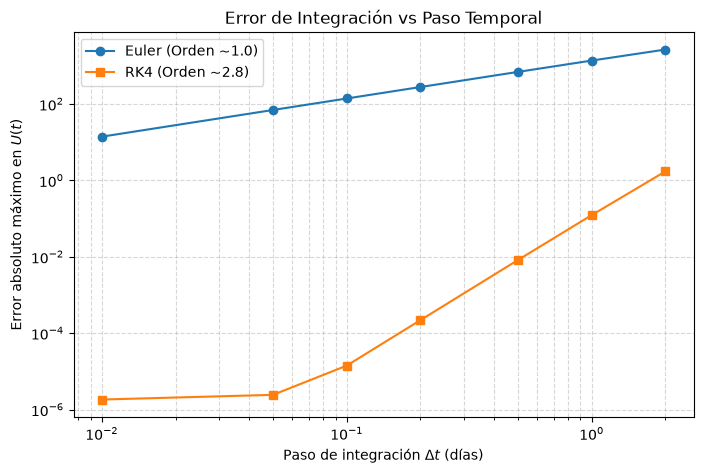

In [4]:
# Presentacion: S15 - DES e Hbridos P1
# Diapositiva 11 - Euler y Runge-Kutta: el orden teorico determina como disminuye el error al reducir dt.
# Contenido: RK4 se compara con solve_ivp como referencia para seleccionar un paso temporal suficientemente preciso.
# Presentacion: S16 - DES e Hbridos P2
# Diapositiva 6 - Modelos dentro de modelos: SD puede evolucionar con su propio reloj dentro de un modelo hibrido.
# Contenido: La integracion numerica avanza la capa SD mientras la capa DES entrega observaciones discretas en las ventanas de acoplamiento.
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Parámetros (Grupo 1)
p = 0.002
q = 0.20
M = 20000
delta_0 = 0.003
U0 = 100.0
T_max = 100.0

# EDO de la capa SD
def dU_dt(t, U):
    return (p + q * (U / M)) * (M - U) - delta_0 * U

# --- a. Implementación de Integradores ---
def euler_step(f, t, y, dt):
    return y + dt * f(t, y)

def rk4_step(f, t, y, dt):
    k1 = f(t, y)
    k2 = f(t + dt/2, y + dt/2 * k1)
    k3 = f(t + dt/2, y + dt/2 * k2)
    k4 = f(t + dt, y + dt * k3)
    return y + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

def integrate(method, f, y0, t_span, dt):
    t_eval = np.arange(t_span[0], t_span[1] + dt, dt)
    y_eval = np.zeros(len(t_eval))
    y_eval[0] = y0
    for i in range(1, len(t_eval)):
        y_eval[i] = method(f, t_eval[i-1], y_eval[i-1], dt)
    return t_eval, y_eval

# Solución de referencia exacta con solve_ivp
sol_exact = solve_ivp(dU_dt, [0, T_max], [U0], method='DOP853', rtol=1e-10, atol=1e-10, dense_output=True)

# --- b. Cálculo de errores máximos para diferentes pasos dt ---
dt_values = np.array([2.0, 1.0, 0.5, 0.2, 0.1, 0.05, 0.01])
errores_euler = []
errores_rk4 = []

for dt in dt_values:
    # Simular
    t_e, y_e = integrate(euler_step, dU_dt, U0, [0, T_max], dt)
    t_rk, y_rk = integrate(rk4_step, dU_dt, U0, [0, T_max], dt)
    
    # Evaluar referencia en los mismos puntos
    y_ref_e = sol_exact.sol(t_e)[0]
    y_ref_rk = sol_exact.sol(t_rk)[0]
    
    # Error absoluto máximo
    err_e = np.max(np.abs(y_e - y_ref_e))
    err_rk = np.max(np.abs(y_rk - y_ref_rk))
    
    errores_euler.append(err_e)
    errores_rk4.append(err_rk)

# Estimación del orden (pendiente en log-log)
# Usamos polyfit: log(error) = orden * log(dt) + C
orden_euler, _ = np.polyfit(np.log(dt_values), np.log(errores_euler), 1)
orden_rk4, _ = np.polyfit(np.log(dt_values), np.log(errores_rk4), 1)

print("--- Análisis de Error de Integración ---")
print(f"Orden estimado Euler: {orden_euler:.2f} (Teórico: 1)")
print(f"Orden estimado RK4  : {orden_rk4:.2f} (Teórico: 4)")

print("\nImpresión de errores para dt = 1.0:")
idx_1 = np.where(dt_values == 1.0)[0][0]
print(f"Error máximo Euler (dt=1): {errores_euler[idx_1]:.4e} usuarios")
print(f"Error máximo RK4   (dt=1): {errores_rk4[idx_1]:.4e} usuarios")

# Generación del gráfico Log-Log
plt.figure(figsize=(8, 5))
plt.plot(dt_values, errores_euler, 'o-', label=f'Euler (Orden ~{orden_euler:.1f})')
plt.plot(dt_values, errores_rk4, 's-', label=f'RK4 (Orden ~{orden_rk4:.1f})')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Paso de integración $\Delta t$ (días)')
plt.ylabel('Error absoluto máximo en $U(t)$')
plt.title('Error de Integración vs Paso Temporal')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

## Task 2.3: Eventos de Estado y Política de Autoescalado

Se implementa la política de autoescalado comparando una detección exacta del evento de estado (cruce del umbral $\rho_{pred} = 0.7$) frente a evaluaciones ingenuas con pasos fijos de tiempo ($\Delta t = 1$ y $\Delta t = 0.25$). 

Se definen tres funciones para ejecutar el lazo acoplado bajo estas lógicas. Cuando se detecta que $\rho_{pred}$ ha superado el umbral entre el tiempo $t$ y $t + \Delta t$, se utiliza el método de bisección para localizar el instante exacto $t_{evento}$, se avanza el reloj hasta ahí, se emite el pedido y se programa el evento de tiempo (la llegada de los servidores en $t_{evento} + D$).

### a. y b. Implementación Exacta e Ingenua
Al ejecutar la siguiente celda se obtienen los resultados de las tres versiones y recolectar el día del primer pedido, la llegada, la latencia máxima y $U(100)$).

In [7]:
# Presentacion: S15 - DES e Hbridos P1
# Diapositiva 13 - Eventos de estado: detectar el cruce de rho_pred = theta y programar una llegada con retardo D.
# Contenido: La busqueda por biseccion localiza el instante del evento y permite comparar la politica exacta con pasos ingenuos.
# Presentacion: S16 - DES e Hbridos P2
# Diapositiva 9 - El reloj de cada modelo: SD usa pasos y DES salta entre eventos.
# Contenido: La deteccion exacta del cruce y la llegada retardada de servidores sincronizan ambos relojes sin perder el evento.
import numpy as np

# Parámetros del grupo 1
p, q, M = 0.002, 0.20, 20000
delta_0, kappa_W, kappa_R = 0.003, 1.0, 0.5
W_ok, a, mu, K = 0.75, 0.0005, 2.0, 60
D, theta = 3, 0.7

def get_W_r(U, c):
    A = a * U / mu
    if A >= c:
        return (5.0, min(1.0, 1 - c/A)) 
    import math
    sum_p = sum((A**i)/math.factorial(i) for i in range(c))
    p_c = (A**c / math.factorial(c)) * (c / (c - A))
    P0 = 1 / (sum_p + p_c)
    C = p_c * P0
    W = (C / (c*mu - a*U)) + (1/mu)
    return W, 0.0

def dU_dt(U, W, r):
    delta = delta_0 + kappa_W * max(0, W - W_ok) + kappa_R * r
    return (p + q * (U / M)) * (M - U) - delta * U

def run_sim(modo="exacto", dt=1.0):
    U, c = 100.0, 4
    t = 0.0
    pedido_pendiente = False
    tiempo_llegada = float('inf')
    
    primer_pedido_t = -1
    llegada_t = -1
    max_W = 0
    
    while t < 100:
        W, r = get_W_r(U, c)
        if W > max_W: max_W = W
            
        # Evento de tiempo: Llegada de servidores (MODO EXACTO)
        if t + dt >= tiempo_llegada and modo == "exacto":
            dt_step = tiempo_llegada - t
            U = U + dU_dt(U, W, r) * dt_step 
            t = tiempo_llegada
            c += 2
            llegada_t = t if llegada_t == -1 else llegada_t
            
            # Regla de reorden inmediato
            if (a * U) / (c * mu) > theta:
                pedido_pendiente = True
                tiempo_llegada = t + D
            else:
                pedido_pendiente = False
                tiempo_llegada = float('inf') # <-- Corrección del bucle infinito
            continue
            
        # Llegada de servidores (MODOS INGENUOS)
        if modo != "exacto" and t >= tiempo_llegada:
            c += 2
            tiempo_llegada = float('inf')
            pedido_pendiente = False
            llegada_t = t if llegada_t == -1 else llegada_t
        
        U_next = U + dU_dt(U, W, r) * dt
        rho_next = (a * U_next) / (c * mu)
        
        # Detección del evento de estado
        if modo == "exacto" and not pedido_pendiente and rho_next > theta:
            t_low, t_high, U_low = t, t + dt, U
            for _ in range(10):
                t_mid = (t_low + t_high) / 2
                U_mid = U + dU_dt(U, W, r) * (t_mid - t)
                if (a * U_mid) / (c * mu) > theta:
                    t_high, U_next = t_mid, U_mid
                else:
                    t_low = t_mid
            t = t_high
            U = U_next
            pedido_pendiente = True
            tiempo_llegada = t + D
            primer_pedido_t = t if primer_pedido_t == -1 else primer_pedido_t
        else:
            t += dt
            U = U_next
            if modo != "exacto" and not pedido_pendiente:
                if (a * U) / (c * mu) > theta:
                    pedido_pendiente = True
                    tiempo_llegada = t + D
                    primer_pedido_t = t if primer_pedido_t == -1 else primer_pedido_t
                    
    return primer_pedido_t, llegada_t, max_W, U

print("Resultados Task 2.3:")
for m, paso in [("ingenuo", 1.0), ("ingenuo", 0.25), ("exacto", 1.0)]:
    p_t, l_t, m_W, U_f = run_sim(modo=m, dt=paso)
    print(f"Modo: {m} (dt={paso}) | 1er Pedido: dia {p_t:.2f} | Llegan: dia {l_t:.2f} | Latencia Max: {m_W:.2f}s | U(100): {U_f:.0f}")

Resultados Task 2.3:
Modo: ingenuo (dt=1.0) | 1er Pedido: dia 24.00 | Llegan: dia 27.00 | Latencia Max: 0.85s | U(100): 19703
Modo: ingenuo (dt=0.25) | 1er Pedido: dia 23.00 | Llegan: dia 26.00 | Latencia Max: 0.82s | U(100): 19703
Modo: exacto (dt=1.0) | 1er Pedido: dia 23.80 | Llegan: dia 26.80 | Latencia Max: 0.87s | U(100): 19703


## Task 2.4: Verificación de la Interfaz entre Capas

Se audita la interfaz de acoplamiento entre System Dynamics y el modelo de eventos discretos. Se verifica estadísticamente que la generación de solicitudes obedece a un proceso de Poisson real y se comprueba la ley de conservación de entidades garantizando que ninguna solicitud desaparece por errores de código.

In [8]:
# Presentacion: S15 - DES e Hbridos P1
# Diapositiva 15 - Interfaz SD-DES: las llegadas se generan como Poisson y cada entidad debe terminar, rechazarse o permanecer en el sistema.
# Contenido: El balance llegadas = terminadas + en_sistema + rechazadas valida que el acoplamiento no pierda solicitudes.
# Presentacion: S16 - DES e Hbridos P2
# Diapositiva 7 - La interfaz debe conservar la poblacion entre modelos.
# Contenido: El balance de llegadas, terminadas, entidades en sistema y rechazadas comprueba que ninguna solicitud desaparezca durante el acoplamiento.
import simpy
import random
import numpy as np

def simular_ventana(lam, c, K=60, warmup=120, duration=720, mu=2.0):
    env = simpy.Environment()
    servers = simpy.Resource(env, capacity=c)
    
    # Contadores
    metrics = {
        'llegadas_totales': 0,
        'llegadas_medicion': 0,
        'terminadas': 0,
        'rechazadas': 0
    }
    
    def source():
        while True:
            yield env.timeout(random.expovariate(lam))
            metrics['llegadas_totales'] += 1
            if env.now > warmup:
                metrics['llegadas_medicion'] += 1
            env.process(customer())
            
    def customer():
        if servers.count + len(servers.queue) < K:
            with servers.request() as req:
                yield req
                yield env.timeout(random.expovariate(mu))
                metrics['terminadas'] += 1
        else:
            metrics['rechazadas'] += 1

    env.process(source())
    env.run(until=duration)
    
    en_sistema = servers.count + len(servers.queue)
    balance = metrics['terminadas'] + en_sistema + metrics['rechazadas']
    conservacion_ok = (balance == metrics['llegadas_totales'])
    
    return metrics['llegadas_medicion'], conservacion_ok, metrics['llegadas_totales'], metrics['terminadas'], en_sistema, metrics['rechazadas']

# --- a. Verificación de Poisson (30 ventanas, lambda = 5) ---
llegadas_medicion_lista = []
duracion_medicion = 720 - 120

for _ in range(30):
    llegadas_obs, _, _, _, _, _ = simular_ventana(lam=5, c=4)
    llegadas_medicion_lista.append(llegadas_obs)

media_obs = np.mean(llegadas_medicion_lista)
var_obs = np.var(llegadas_medicion_lista)
esperado = 5 * duracion_medicion

print("--- a. Verificación del Proceso de Poisson ---")
print(f"Llegadas esperadas (lam * T) : {esperado}")
print(f"Media observada en 30 rep    : {media_obs:.2f}")
print(f"Varianza observada           : {var_obs:.2f}\n")

# --- b. Conservación de Entidades (10 ventanas con sobrecarga, lambda = 10) ---
print("--- b. Conservación de Entidades (sobrecarga lambda = 10) ---")
print(f"{'Ventana':<8} | {'Llegadas':<10} | {'Terminadas':<10} | {'En Sist.':<10} | {'Rechazadas':<10} | {'Balance OK'}")
print("-" * 75)

for i in range(1, 11):
    _, balance_ok, llegadas, terminadas, en_sist, rechazadas = simular_ventana(lam=10, c=4)
    print(f"{i:<8} | {llegadas:<10} | {terminadas:<10} | {en_sist:<10} | {rechazadas:<10} | {balance_ok}")

--- a. Verificación del Proceso de Poisson ---
Llegadas esperadas (lam * T) : 3000
Media observada en 30 rep    : 2995.43
Varianza observada           : 2564.11

--- b. Conservación de Entidades (sobrecarga lambda = 10) ---
Ventana  | Llegadas   | Terminadas | En Sist.   | Rechazadas | Balance OK
---------------------------------------------------------------------------
1        | 7239       | 5673       | 49         | 1517       | True
2        | 7157       | 5921       | 57         | 1179       | True
3        | 7114       | 5761       | 59         | 1294       | True
4        | 7231       | 5790       | 56         | 1385       | True
5        | 7095       | 5748       | 57         | 1290       | True
6        | 7160       | 5792       | 60         | 1308       | True
7        | 7087       | 5816       | 56         | 1215       | True
8        | 7150       | 5663       | 54         | 1433       | True
9        | 7190       | 5766       | 55         | 1369       | True
10       | 712

## Task 3.1: Dependencia del Tamaño de la Ventana ($H$)

Evalúa el impacto de la longitud de la ventana de intercambio $H$ en el comportamiento del modelo híbrido. Ejecuta 20 réplicas para cada valor de $H$, calculando $U(100)$, la latencia máxima y el error cuadrático medio (RMSE) de la trayectoria de usuarios en comparación con la media del caso base $H=0.25$.

Iniciando simulaciones. Esto puede tomar unos minutos...
H=0.25 procesado. U(100)=19703
H=0.5 procesado. U(100)=19703
H=1 procesado. U(100)=19703
H=2 procesado. U(100)=19703
H=4 procesado. U(100)=19703
H=7 procesado. U(100)=19703

--- Resultados de Ventana H ---
H=0.25 | U(100): 19703 ± 0 | W max: 0.94 ± 0.05s | RMSE: 0.0 ± 0.0
H=0.5  | U(100): 19703 ± 0 | W max: 0.92 ± 0.04s | RMSE: 95.0 ± 22.8
H=1    | U(100): 19703 ± 0 | W max: 0.92 ± 0.06s | RMSE: 241.2 ± 121.7
H=2    | U(100): 19703 ± 0 | W max: 0.85 ± 0.04s | RMSE: 360.9 ± 108.1
H=4    | U(100): 19703 ± 0 | W max: 0.86 ± 0.04s | RMSE: 907.2 ± 304.1
H=7    | U(100): 19703 ± 0 | W max: 0.60 ± 0.01s | RMSE: 338.4 ± 0.0


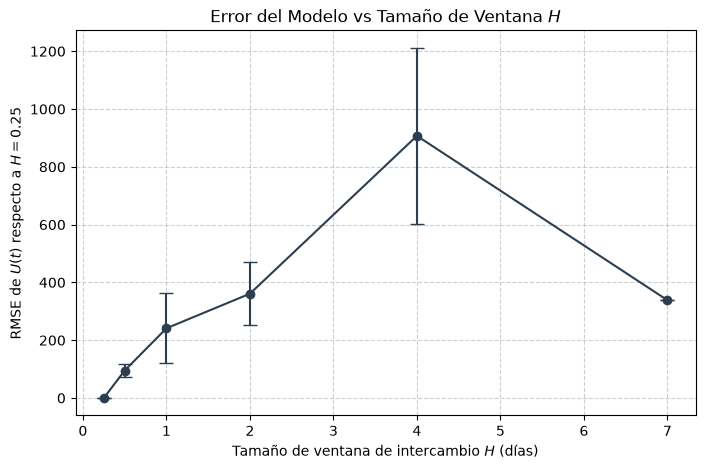

In [9]:
import numpy as np
import simpy
import random
import scipy.stats as st
import matplotlib.pyplot as plt

# Presentacion: S15 - DES e Hbridos P1
# Diapositiva 18 - Ventana de intercambio H: un H pequeno aproxima mejor la interaccion continua, pero aumenta el costo computacional.
# Contenido: Se comparan replicas para distintos H mediante U(100), latencia maxima y RMSE respecto al caso base.
# Presentacion: S16 - DES e Hbridos P2
# Diapositiva 9 - El tamano de la ventana H controla la precision, el costo y el retraso del intercambio.
# Contenido: Variar H y medir RMSE permite verificar la sensibilidad del acoplamiento y comprobar la convergencia hacia una ventana pequena.
# Presentacion: S16 - DES e Hbridos P2
# Diapositiva 10 - Un hibrido que se puede defender: la solucion debe mantenerse al reducir la ventana.
# Contenido: La comparacion con H = 0.25 como referencia evalua si el comportamiento de usuarios y latencia es robusto al sincronizar con mayor frecuencia.
# Parámetros globales (Grupo 1)
M, p, q, delta_0 = 20000, 0.002, 0.20, 0.003
kappa_W, kappa_R, W_ok = 1.0, 0.5, 0.75
a, mu, K, D, theta = 0.0005, 2.0, 60, 3, 0.7
T_max = 100

def simular_ventana_des(lam, c, warmup=120, duration=720):
    env = simpy.Environment()
    servers = simpy.Resource(env, capacity=c)
    metrics = {'arrived': 0, 'accepted': 0, 'latencies': []}
    
    def source():
        while True:
            t_inter = random.expovariate(lam) if lam > 0 else float('inf')
            yield env.timeout(t_inter)
            metrics['arrived'] += 1
            env.process(customer())
            
    def customer():
        if servers.count + len(servers.queue) < K:
            metrics['accepted'] += 1
            arr_time = env.now
            with servers.request() as req:
                yield req
                yield env.timeout(random.expovariate(mu))
                if arr_time >= warmup:
                    metrics['latencies'].append(env.now - arr_time)

    if lam > 0:
        env.process(source())
    env.run(until=duration)
    
    W = np.mean(metrics['latencies']) if metrics['latencies'] else 0.0
    r = 1.0 - (metrics['accepted'] / metrics['arrived']) if metrics['arrived'] > 0 else 0.0
    return W, r

def dU_dt(U, W, r):
    delta = delta_0 + kappa_W * max(0, W - W_ok) + kappa_R * r
    return (p + q * (U / M)) * (M - U) - delta * U

def rk4_step(U, W, r, dt):
    k1 = dU_dt(U, W, r)
    k2 = dU_dt(U + dt/2 * k1, W, r)
    k3 = dU_dt(U + dt/2 * k2, W, r)
    k4 = dU_dt(U + dt * k3, W, r)
    return U + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

def run_hybrid_replica(H):
    U, c = 100.0, 4
    t = 0.0
    pedido_pendiente = False
    tiempo_llegada = float('inf')
    
    t_grid = np.arange(0, T_max + 1, 1.0)
    U_grid = np.zeros_like(t_grid)
    U_grid[0] = U
    grid_idx = 1
    
    max_W = 0.0
    dt_rk4 = min(0.25, H) 
    
    while t < T_max:
        W, r = simular_ventana_des(a * U, c)
        if W > max_W: max_W = W
        
        t_next_window = min(t + H, T_max)
        
        while t < t_next_window - 1e-9:
            dt_step = min(dt_rk4, t_next_window - t)
            
            # Evento temporal: Llegada de servidores
            if pedido_pendiente and t + dt_step >= tiempo_llegada:
                dt_to_arrival = tiempo_llegada - t
                U = rk4_step(U, W, r, dt_to_arrival)
                t = tiempo_llegada
                c += 2
                pedido_pendiente = False
                tiempo_llegada = float('inf')
                
                # Reorden
                if (a * U) / (c * mu) > theta:
                    pedido_pendiente = True
                    tiempo_llegada = t + D
                
                while grid_idx < len(t_grid) and t_grid[grid_idx] <= t:
                    U_grid[grid_idx] = U
                    grid_idx += 1
                continue
            
            U = rk4_step(U, W, r, dt_step)
            t += dt_step
            
            # Evento de estado: Umbral de pedido
            if not pedido_pendiente and (a * U) / (c * mu) > theta:
                pedido_pendiente = True
                tiempo_llegada = t + D
                
            while grid_idx < len(t_grid) and t_grid[grid_idx] <= t:
                U_grid[grid_idx] = U
                grid_idx += 1
                
    return U_grid, max_W

def confidence_interval(data, conf=0.95):
    a = np.array(data)
    n = len(a)
    m, se = np.mean(a), st.sem(a)
    h = se * st.t.ppf((1 + conf) / 2., n-1)
    return m, h

# --- Ejecución del Experimento ---
H_values = [0.25, 0.5, 1, 2, 4, 7]
replicas = 20
resultados = {}

print("Iniciando simulaciones. Esto puede tomar unos minutos...")

# Obtener referencia con H = 0.25
ref_trajectories = []
ref_W = []
for _ in range(replicas):
    U_traj, m_W = run_hybrid_replica(0.25)
    ref_trajectories.append(U_traj)
    ref_W.append(m_W)
U_ref_mean = np.mean(ref_trajectories, axis=0)

W_m, W_h = confidence_interval(ref_W)
U100_m, U100_h = confidence_interval([traj[-1] for traj in ref_trajectories])
resultados[0.25] = {'U100': (U100_m, U100_h), 'W_max': (W_m, W_h), 'RMSE': (0.0, 0.0)}
print(f"H=0.25 procesado. U(100)={U100_m:.0f}")

# Evaluar el resto de las ventanas
for H in H_values[1:]:
    U100_list, W_list, rmse_list = [], [], []
    for _ in range(replicas):
        U_traj, m_W = run_hybrid_replica(H)
        U100_list.append(U_traj[-1])
        W_list.append(m_W)
        rmse = np.sqrt(np.mean((U_traj - U_ref_mean)**2))
        rmse_list.append(rmse)
        
    resultados[H] = {
        'U100': confidence_interval(U100_list),
        'W_max': confidence_interval(W_list),
        'RMSE': confidence_interval(rmse_list)
    }
    print(f"H={H} procesado. U(100)={resultados[H]['U100'][0]:.0f}")

# Imprimir Resumen
print("\n--- Resultados de Ventana H ---")
for H in H_values:
    u, uh = resultados[H]['U100']
    w, wh = resultados[H]['W_max']
    rm, rmh = resultados[H]['RMSE']
    print(f"H={H:<4} | U(100): {u:.0f} ± {uh:.0f} | W max: {w:.2f} ± {wh:.2f}s | RMSE: {rm:.1f} ± {rmh:.1f}")

# Gráfico de Error RMSE vs H
errores = [resultados[H]['RMSE'][0] for H in H_values]
errores_h = [resultados[H]['RMSE'][1] for H in H_values]

plt.figure(figsize=(8, 5))
plt.errorbar(H_values, errores, yerr=errores_h, fmt='o-', capsize=5, color='#2c3e50')
plt.xlabel('Tamaño de ventana de intercambio $H$ (días)')
plt.ylabel('RMSE de $U(t)$ respecto a $H=0.25$')
plt.title('Error del Modelo vs Tamaño de Ventana $H$')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()